# Google Colab edition — MIT Lab 1 music generation

Run the shared setup and every exercise cell in a GPU runtime. Full mode uses the complete original Irish corpus and 3,000 optimizer updates. Generated audio and the duration/temperature experiment artifacts are required before completion is recorded.


In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '02_mit_6s191', 'tensorflow', '02_tf_music_generation.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/02_mit_6s191
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/02_mit_6s191/results


In [2]:
from datetime import datetime, timezone
import json, uuid, platform, importlib.metadata, importlib.util
from pathlib import Path
assert not QUICK_RUN, "Full exercise completion requires QUICK_RUN=False."
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '-' + uuid.uuid4().hex[:6]
RUN_DIR = Path('results') / Path(COLAB_CONTEXT['run']['notebook']).stem / RUN_ID
MODEL_DIR = Path('models') / Path(COLAB_CONTEXT['run']['notebook']).stem / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
TASK_EVIDENCE = {}
def record_task(name, **evidence):
    TASK_EVIDENCE[name] = evidence
    (RUN_DIR / 'task_evidence.json').write_text(json.dumps(TASK_EVIDENCE, indent=2, default=str))
def complete_notebook(required):
    missing = [key for key in required if key not in TASK_EVIDENCE]
    if missing:
        raise RuntimeError('Required exercise outputs are missing: ' + ', '.join(missing))
    COLAB_CONTEXT['run']['exercise_evidence'] = TASK_EVIDENCE
    COLAB_CONTEXT['run']['artifact_folder'] = str(RUN_DIR)
    COLAB_CONTEXT['run']['full_real_data_exercise_checks_passed'] = True
    COLAB_CONTEXT['run']['execution_environment'] = {
        'in_colab': IN_COLAB, 'python': platform.python_version(),
        'platform': platform.platform(), 'run_id': RUN_ID,
    }
    COLAB_CONTEXT['run']['execution_environment']['packages'] = {
        package: importlib.metadata.version(package)
        for package in ['numpy','pandas','tensorflow','torch','mitdeeplearning','transformers','peft']
        if importlib.util.find_spec(package.replace('-', '_')) is not None
    }
    finish_run(COLAB_CONTEXT)
    print('Required exercise checks passed. Artifacts:', RUN_DIR)

# MIT Lab 1, Part 2 — TensorFlow music generation

Exercise source: https://github.com/MITDeepLearning/introtodeeplearning/blob/master/lab1/TF_Part2_Music_Generation.ipynb

This compact adaptation implements vectorization, shifted sequence batches, embedding/LSTM/output layers, categorical cross entropy, gradient optimization, checkpoints, autoregressive generation, and playable audio. It retains the original course corpus from mitdeeplearning 0.7.5. Training duration and sampling temperature are compared with actual 1,000- and 3,000-update checkpoints. Local artifact logging replaces Comet. QUICK_RUN must be false. Invalid generated music is reported as incomplete rather than replaced with a training song.

© MIT Introduction to Deep Learning, MIT License. http://introtodeeplearning.com


Full mode trains 3,000 steps on the complete packaged course corpus. Checkpoints at 1,000 and 3,000 steps support duration and temperature experiments. Audio conversion must succeed before the final completion record.


In [3]:
import os, json, random, shutil, subprocess, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
SEED = 42
random.seed(SEED); np.random.seed(SEED)
# This is the original Irish folk-song corpus, not synthetic music.
text = Path('data/irish.abc').read_text(encoding='utf-8')
songs = [s.strip() for s in text.split('\n\n') if s.strip()]
songs_joined = '\n\n'.join(songs)
vocab = sorted(set(songs_joined))
char2idx = {c:i for i,c in enumerate(vocab)}
idx2char = np.array(vocab)
assert len(songs) > 500 and len(songs_joined) > 100000
def vectorize_string(string):
    return np.array([char2idx[c] for c in string], dtype=np.int64)
vectorized_songs = vectorize_string(songs_joined)
def get_batch_array(data, seq_length, batch_size):
    starts = np.random.randint(0, len(data)-seq_length, size=batch_size)
    positions = starts[:,None] + np.arange(seq_length)[None,:]
    return data[positions], data[positions+1]
x_check, y_check = get_batch_array(vectorized_songs, 10, 2)
assert x_check.shape == y_check.shape == (2,10)
assert np.array_equal(x_check[:,1:], y_check[:,:-1])
assert ''.join(idx2char[vectorized_songs[:40]]) == songs_joined[:40]
record_task('vectorisation_and_batches', real_corpus=True, songs=len(songs),
            characters=len(songs_joined), vocabulary=len(vocab), batch_shape=[2,10])
print(TASK_EVIDENCE['vectorisation_and_batches'])

{'real_corpus': True, 'songs': 806, 'characters': 197605, 'vocabulary': 83, 'batch_shape': [2, 10]}


In [4]:
os.environ['KERAS_BACKEND']='tensorflow'
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
assert tf.config.list_physical_devices('GPU'), 'Select a GPU Colab runtime.'
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
def build_model(vocab_size,embedding_dim,rnn_units,batch_size):
    return tf.keras.Sequential([
        tf.keras.Input(batch_shape=(batch_size,None),dtype=tf.int32),
        tf.keras.layers.Embedding(vocab_size,embedding_dim),
        tf.keras.layers.LSTM(rnn_units,return_sequences=True,stateful=True,
            recurrent_initializer='glorot_uniform',recurrent_activation='sigmoid'),
        tf.keras.layers.Dense(vocab_size)])
params={'seed':SEED,'iterations':3000,'batch_size':8,'seq_length':100,
        'embedding_dim':256,'rnn_units':1024,'learning_rate':0.003,'smoke':False}
model=build_model(len(vocab),params['embedding_dim'],params['rnn_units'],params['batch_size'])
x,y=get_batch_array(vectorized_songs,100,8)
assert tuple(model(x).shape)==(8,100,len(vocab))
model.summary()
record_task('model_shapes',input_shape=list(x.shape),logits_shape=[8,100,len(vocab)],gpu=True)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (8, None, 256)         │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (8, None, 1024)        │     5,246,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (8, None, 83)          │        85,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,353,299 (20.42 MB)

 Trainable params: 5,353,299 (20.42 MB)

 Non-trainable params: 0 (0.00 B)

  0%|          | 0/3000 [00:00<?, ?it/s]

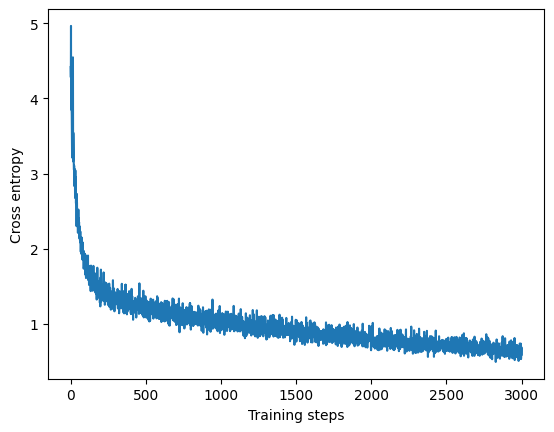

Final training loss: 0.5880795121192932 ; checkpoint restoration passed.


In [5]:
from tqdm.auto import trange
def compute_loss(labels,logits):
    return tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(labels,logits,from_logits=True))
optimizer=tf.keras.optimizers.Adam(params['learning_rate'])
@tf.function
def train_step(x,y):
    # Independently sampled batches do not represent continuous songs.
    for layer in model.layers:
        if hasattr(layer,'reset_states'): layer.reset_states()
    with tf.GradientTape() as tape:
        loss=compute_loss(y,model(x,training=True))
    gradients=tape.gradient(loss,model.trainable_variables)
    gradients,_=tf.clip_by_global_norm(gradients,1.)
    optimizer.apply_gradients(zip(gradients,model.trainable_variables))
    return loss
history=[]
for step in trange(1,params['iterations']+1):
    x,y=get_batch_array(vectorized_songs,params['seq_length'],params['batch_size'])
    loss=float(train_step(x,y)); assert np.isfinite(loss)
    history.append({'step':step,'loss':loss})
    if step in [1000,3000]: model.save_weights(MODEL_DIR/f'checkpoint_{step}.weights.h5')
pd.DataFrame(history).to_csv(RUN_DIR/'training.csv',index=False)
(RUN_DIR/'config.json').write_text(json.dumps(params,indent=2))
def restore_snapshot(steps):
    global restored
    restored=build_model(len(vocab),params['embedding_dim'],params['rnn_units'],1)
    restored.load_weights(MODEL_DIR/f'checkpoint_{steps}.weights.h5')
restore_snapshot(3000)
for a,b in zip(model.get_weights(),restored.get_weights()): assert np.array_equal(a,b)
plt.plot([h['step'] for h in history],[h['loss'] for h in history]);plt.xlabel('Training steps');plt.ylabel('Cross entropy')
plt.savefig(RUN_DIR/'training_loss.png');plt.show()
record_task('training_and_checkpoint',steps=len(history),full_iterations=3000,
            final_loss=history[-1]['loss'],checkpoint_round_trip=True)
print('Final training loss:',history[-1]['loss'],'; checkpoint restoration passed.')

In [6]:
def generate_text(model,start_string,generation_length=1000,temperature=1.):
    for layer in model.layers:
        if hasattr(layer,'reset_states'): layer.reset_states()
    tokens=tf.constant(vectorize_string(start_string)[None,:],dtype=tf.int32); chars=[]
    for _ in range(generation_length):
        logits=model(tokens,training=False)[:,-1,:]
        next_id=int(tf.random.categorical(logits/temperature,1)[0,0])
        tokens=tf.constant([[next_id]],dtype=tf.int32)
        chars.append(idx2char[next_id])
    return start_string+''.join(chars)
generated_text=generate_text(restored,'X',1000)
assert len(generated_text)==1001
(RUN_DIR/'generated_text.abc').write_text(generated_text,encoding='utf-8')
print(generated_text[:500])
record_task('autoregressive_sampling',sampled_characters=1000,recurrent_state_carried=True)

X:20
T:Master McCamer
Z: id:dc-jig-96
M:6/8
L:1/8
K:D Major
f|e2 fe dc|d2 f2 a2|gf ga g2|a4 g2|f3 g f2|!
g2 f2 g2|a2 f2 dg|e2 cd e2|e2 f2 e2|d4|]!
cB|A2 f2 f2|A2 f2 f2|A2 f2 f2|A2 d3/2c|!
d2 Bd d2|d2 f2 A2|B2 c2 d2|e4 d2|e4|]!

X:6
T:Bally Hamey's
Z: id:dc-jig-26
M:6/8
L:1/8
K:D Major
A,|D2FA D2FA|d2fe afef|g2eg f2ed|BABA GFED|!
D2FA D2FA|d2cB ABdf|eBB2 A2FA|BAGF G2:|!
(3def|gfed ^cbag|fgaf bagf|egfg ecc2|d6cA d^cde|!
Afff afdf|gfgb afdf|ecc2 eaa2|gagf e3|]!

X:3
T:Alice's
Z: id:dc-reel-265
M:C



In [7]:
# Generated songs must actually convert to playable audio for this task.
if not shutil.which('abc2midi') or not shutil.which('timidity'):
    if not IN_COLAB:
        raise RuntimeError('Run this audio exercise in Colab or install abcmidi/timidity.')
    subprocess.run(['apt-get', '-qq', 'update'], check=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'abcmidi', 'timidity', 'fluid-soundfont-gm'], check=True)
soundfonts = list(Path('/usr/share/sounds/sf2').glob('*.sf2'))
timidity_args = []
if soundfonts:
    config = RUN_DIR / 'timidity.cfg'
    config.write_text('soundfont ' + str(soundfonts[0]) + '\n')
    timidity_args = ['-c', str(config)]
def make_audio(generated, label):
    # Keep complete generated ABC tune blocks. No training tune is substituted.
    blocks = re.split(r'(?m)(?=^X:)', generated)
    candidates = [b.strip() for b in blocks if b.lstrip().startswith('X:') and re.search(r'(?m)^K:',b)]
    for index, song in enumerate(candidates):
        abc = RUN_DIR / f'{label}_{index}.abc'
        midi = abc.with_suffix('.mid'); wav = abc.with_suffix('.wav')
        abc.write_text(song + '\n', encoding='utf-8')
        conversion = subprocess.run(['abc2midi',str(abc),'-o',str(midi)],capture_output=True,text=True,timeout=60)
        (abc.with_suffix('.conversion.log')).write_text(conversion.stdout + conversion.stderr)
        if conversion.returncode == 0 and midi.is_file() and midi.stat().st_size > 50:
            synthesis = subprocess.run(['timidity',*timidity_args,str(midi),'-Ow','-o',str(wav)],
                                       capture_output=True,text=True,timeout=60)
            if synthesis.returncode == 0 and wav.is_file() and wav.stat().st_size > 1000:
                from scipy.io import wavfile
                rate, samples = wavfile.read(wav)
                if samples.size and np.any(samples):
                    display(Audio(filename=str(wav)))
                    return {'abc':str(abc),'midi':str(midi),'wav':str(wav),
                            'duration_seconds':len(samples)/rate,'sample_rate':int(rate)}
    return None
audio_results = []
sampling_experiments = []
for steps in [1000,3000]:
    restore_snapshot(steps)
    for temperature in [0.8,1.0]:
        # This prompt is only a seed; all subsequent 1,000 characters are sampled.
        seed = 'X:1\nT:Generated\nM:4/4\nL:1/8\nK:D\n'
        generated = generate_text(restored, seed, 1000, temperature)
        assert len(generated) == len(seed)+1000
        path = RUN_DIR / f'generated_{steps}_temperature_{temperature}.abc'
        path.write_text(generated, encoding='utf-8')
        playback = make_audio(generated, f'steps_{steps}_temperature_{temperature}')
        sampling_experiments.append({'training_steps':steps,'temperature':temperature,
                                     'seed':seed,'generated_characters':1000,
                                     'generated_text':str(path),'audio':playback})
        if playback: audio_results.append(playback)
    del restored
# Resample the fully trained model if a particular draw did not contain a valid song.
restore_snapshot(3000)
for attempt in range(16):
    if audio_results: break
    generated = generate_text(restored, 'X', 1000, 0.8)
    playback = make_audio(generated, f'additional_sample_{attempt}')
    if playback: audio_results.append(playback)
pd.DataFrame([{k:v for k,v in x.items() if k!='audio'} for x in sampling_experiments]).to_csv(
    RUN_DIR/'sampling_experiments.csv',index=False)
(RUN_DIR/'generated_audio.json').write_text(json.dumps(audio_results,indent=2))
if not audio_results:
    raise RuntimeError('No valid generated song converted to audio. Train longer, then sample again; this exercise is incomplete.')
record_task('generated_audio', files=audio_results, generated_not_training_music=True)
record_task('hyperparameter_experiments', comparisons=sampling_experiments,
            design='Training duration 1000 vs 3000 steps and sampling temperature 0.8 vs 1.0.')
print('Playable generated songs:',len(audio_results))

<IPython.lib.display.Audio object>

<IPython.lib.display.Audio object>

<IPython.lib.display.Audio object>

Playable generated songs: 4


In [8]:
complete_notebook(['vectorisation_and_batches','model_shapes','training_and_checkpoint','autoregressive_sampling','generated_audio','hyperparameter_experiments'])

Saved run settings. Save the notebook in Colab to keep its cell outputs.
Required exercise checks passed. Artifacts: results/02_tf_music_generation/20261003T064447-ec95fe


In [9]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
}
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": "tensorflow", "legacy_keras": null}
